# Phase 5 · Tuning with nested cross-validation

**Project 1 · FAA · breast_cancer (classification)**

**What this notebook does:** it searches for the best hyperparameters of each learner and for the threshold that minimizes the cost, **without looking at the outer validation or the test set**. It saves the predictions so the learners can be compared in Phase 6.

**Protocol (for each of the 25 outer folds):**
1. `GridSearchCV` with 3 inner folds chooses hyperparameters by **MCC**.
2. With out-of-sample probabilities from the same training part, the **cost threshold** is chosen.
3. The model scores the outer validation fold, once.

**We do not compare learners yet.** That is Phase 6.

**Requires** `utils_python.py` and `models_python.py` in the same folder.

### Cell 1: import the libraries

We import the libraries and the functions from earlier phases: `utils_python.py` (Phase 3) and `models_python.py` (Phase 4).

In [1]:
import os  # os: configure the environment
import time  # time: measure how long things take
import warnings  # warnings: silence repetitive warnings
import numpy as np  # numpy: numerical computing with arrays
import polars as pl  # polars: result tables
import matplotlib.pyplot as plt  # matplotlib: draws the plots
from sklearn.base import clone  # clone: copies a model without training
from sklearn.metrics import make_scorer, matthews_corrcoef  # MCC as the selection criterion
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, validation_curve  # tuning and validation curves with cross-validation
from utils_python import load_data, make_folds, compute_metrics, best_threshold  # functions from Phase 3
from models_python import learners  # the five learners and their grids (Phase 4)
os.environ["PYTHONWARNINGS"] = "ignore"  # parallel processes should not print warnings either
warnings.filterwarnings("ignore")  # silence repetitive convergence warnings

### Cell 2: load data, folds and learners

We load the data and recreate the **25 outer folds**. The test set (114 rows) is still unused.

In [2]:
X_train, X_test, y_train, y_test, columns, path = load_data()  # same 455/114 split
folds = make_folds(X_train, y_train)  # the 25 OUTER folds of Phase 3
results_dir = path.parent.parent / "results"  # folder for tables
figures_dir = path.parent.parent / "figures" / "05_tuning"  # folder for plots
results_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
figures_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
print("Outer folds:", len(folds), "| learners:", list(learners))  # reminder
print("The test set (", len(y_test), "rows) is still untouched")  # reminder

Outer folds: 25 | learners: ['tree', 'mlp', 'evolutionary', 'bayes', 'svm']
The test set ( 114 rows) is still untouched


### Cell 3: ONE fold step by step · split the outer fold

## One fold step by step

**What nested cross-validation is.** There are two levels:

```
OUTER fold (25)  ──►  measures performance: 364 rows to learn from, 91 to evaluate
   └── inside the training part (364):
        INNER fold (3) ──►  chooses the hyperparameters and the threshold
```

**Why two levels:** if we choose hyperparameters and evaluate with the same data, the result is optimistic. The 91 outer-validation tumours **take no part** in any choice.

First we split outer fold 0.

In [3]:
fold_number = 0  # choose the first outer fold
train_idx, val_idx = folds[fold_number]  # its training and validation rows
X_tr, y_tr = X_train[train_idx], y_train[train_idx]  # data to learn from and tune on (364 rows)
X_va, y_va = X_train[val_idx], y_train[val_idx]  # data to evaluate on (91 rows): NOT touched until the end
print("Fold training set:", len(y_tr), "| outer validation:", len(y_va))  # sizes

Fold training set: 364 | outer validation: 91


### Cell 4: ONE fold step by step · choose hyperparameters (INNER validation)

**Step 1 · choose hyperparameters.** `GridSearchCV` tries the 80 SVM combinations with 3 inner folds and keeps the one with the best **MCC**.

In [4]:
family, pipeline, grid = learners["svm"]  # example with the analogizer (SVM)
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # 3 INNER folds, only inside the training part
search = GridSearchCV(clone(pipeline), grid, scoring=make_scorer(matthews_corrcoef), cv=inner, n_jobs=-1)  # tries every combination and scores it with MCC
search.fit(X_tr, y_tr)  # the outer validation does NOT take part
print("Combinations tried:", len(search.cv_results_["params"]), "| fits:", len(search.cv_results_["params"]) * 3)  # 80 x 3
print("Best inner MCC:", round(search.best_score_, 3))  # the best score reached inside the training part
for name, value in search.best_params_.items():  # show the best combination
    print(" ", name, "=", "log1p" if hasattr(value, "func") else value)  # name and chosen value

Combinations tried: 80 | fits: 240
Best inner MCC: 0.965
  log1p = passthrough
  model__estimator__C = 10.0
  model__estimator__gamma = 0.03


**What we see:** in this fold the winner is `C = 10`, `gamma = 0.03` and no `log1p`, with an inner MCC of 0.965 after 240 fits (80 combinations × 3).

### Cell 5: ONE fold step by step · choose the threshold by cost

**Step 2 · choose the threshold.** With the probabilities of tumours that each model did *not* see (inner validation) we look for the threshold that minimizes the cost (5·FN + FP)/n. Only the training part is used.

In [5]:
final_model = search.best_estimator_  # the best model, already retrained with the whole fold training set
out_of_fold = cross_val_predict(clone(final_model), X_tr, y_tr, cv=inner, method="predict_proba")[:, 1]  # probabilities of tumours that each model did NOT see
threshold = best_threshold(y_tr, out_of_fold)  # threshold that minimizes the cost, using only the training part
print("Chosen threshold:", threshold)  # usually lower than 0.5

Chosen threshold: 0.39


**What we see:** the chosen threshold is 0.39, below 0.5: giving a few false alarms is cheaper than letting a malignant tumour slip away.

### Cell 6: ONE fold step by step · score the outer validation (only once)

**Step 3 · evaluate.** Now yes: the chosen model scores the 91 outer-validation tumours, which never influenced anything.

In [6]:
prob_va = final_model.predict_proba(X_va)[:, 1]  # probability of malignant for the 91 validation tumours
for name, t in [("threshold 0.5", 0.5), ("cost threshold", threshold)]:  # the two thresholds
    m = compute_metrics(y_va, prob_va, t)  # metrics with that threshold
    print(f"{name}: MCC {m['mcc']:.3f} | recall {m['recall']:.3f} | FN {m['fn']} | FP {m['fp']} | cost {m['cost']:.3f}")  # result

threshold 0.5: MCC 0.931 | recall 0.912 | FN 3 | FP 0 | cost 0.165
cost threshold: MCC 0.931 | recall 0.912 | FN 3 | FP 0 | cost 0.165


**What we see:** MCC 0.931 with 3 false negatives and 0 false positives. In this particular fold both thresholds give the same result; this will not always be the case.

### Cell 7: the same recipe as a function (to repeat it on the 25 folds and the 5 learners)

We put the three steps into one function and check it with Naive Bayes. This way it is repeated identically for all learners.

In [7]:
def label(value):  # makes hyperparameter values readable
    if isinstance(value, str):  # "passthrough" means "untransformed"
        return "no log1p" if value == "passthrough" else value  # readable name
    return "log1p" if hasattr(value, "func") else str(value)  # log1p or the value as text

def tune_fold(key, fold_number):  # tunes one learner on one outer fold
    family, pipeline, grid = learners[key]  # pipeline and grid of the learner
    train_idx, val_idx = folds[fold_number]  # rows of the fold
    X_tr, y_tr, X_va, y_va = X_train[train_idx], y_train[train_idx], X_train[val_idx], y_train[val_idx]  # split
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # inner validation
    start = time.perf_counter()  # start the clock
    search = GridSearchCV(clone(pipeline), grid, scoring=make_scorer(matthews_corrcoef), cv=inner, n_jobs=-1).fit(X_tr, y_tr)  # 1) choose hyperparameters
    out_of_fold = cross_val_predict(clone(search.best_estimator_), X_tr, y_tr, cv=inner, method="predict_proba")[:, 1]  # 2) out-of-sample probabilities
    threshold = best_threshold(y_tr, out_of_fold)  # 2) cost threshold
    seconds = time.perf_counter() - start  # total tuning time
    prob_va = search.best_estimator_.predict_proba(X_va)[:, 1]  # 3) score the outer validation
    row = {"learner": key, "fold": fold_number, "threshold": threshold, "inner_mcc": float(search.best_score_), "seconds": seconds}  # fold data
    for prefix, t in [("t05", 0.5), ("tcost", threshold)]:  # metrics with the two thresholds
        row.update({f"{prefix}_{k}": v for k, v in compute_metrics(y_va, prob_va, t).items()})  # add each metric
    row["params"] = "; ".join(f"{k.replace('model__', '').replace('estimator__', '')}={label(v)}" for k, v in search.best_params_.items())  # chosen hyperparameters
    scores = [{"learner": key, "fold": fold_number, "row": int(i), "y": int(y), "score": float(p)} for i, y, p in zip(val_idx, y_va, prob_va)]  # one line per tumour
    return row, scores  # return results

test_row, _ = tune_fold("bayes", 0)  # check the function with a fast learner
print("Naive Bayes, fold 0 ->", test_row["params"], "| threshold", test_row["threshold"])  # result of the check

Naive Bayes, fold 0 -> log1p=log1p; var_smoothing=1e-11 | threshold 0.03


**What we see:** Naive Bayes chooses `log1p` and `var_smoothing = 1e-11`, with a threshold of only 0.03.

### Cell 8: full tuning (5 learners x 25 folds)

**The full tuning:** 5 learners × 25 folds. It takes a few minutes. It saves two tables for Phase 6: the metrics per fold and the probability each model gave to each validation tumour.

In [8]:
rows, all_scores = [], []  # here we accumulate the results
total_start = time.perf_counter()  # overall clock
for key in learners:  # loop over the five learners
    start = time.perf_counter()  # the learner's clock
    for n in range(len(folds)):  # loop over the 25 outer folds
        row, scores = tune_fold(key, n)  # tune this fold
        rows.append(row)  # store the row
        all_scores.extend(scores)  # store the scores
    print(f"{key:12s} finished in {time.perf_counter() - start:5.1f} s")  # progress
print(f"Total time: {(time.perf_counter() - total_start) / 60:.1f} min")  # total time
results = pl.from_dicts(rows, infer_schema_length=None)  # table with one row per (learner, fold)
outer_scores = pl.from_dicts(all_scores)  # table with one row per (learner, fold, tumour)
results.write_csv(results_dir / "outer_folds.csv")  # save for Phase 6
outer_scores.write_csv(results_dir / "outer_scores.csv")  # save for Phase 6
print("Saved in:", results_dir)  # where

tree         finished in  38.0 s


mlp          finished in 115.6 s


evolutionary finished in  61.2 s


bayes        finished in  32.1 s


svm          finished in  76.7 s
Total time: 5.4 min
Saved in: results


**What we see:** about 5 minutes in total with 4 cores (a laptop with fewer cores will take longer). **Limit:** the assignment asks for "a few minutes"; this is at the edge.

### Cell 9: how much does the tuning cost?

How much does the tuning cost? We also show the mean inner MCC (**optimistic**: it is the best of the grid, and is not valid for comparison).

In [9]:
for key, (family, _, grid) in learners.items():  # loop over the five
    sub = results.filter(pl.col("learner") == key)  # its 25 rows
    n_comb = int(np.prod([len(v) for v in grid.values()]))  # combinations in its grid
    print(f"{family:13s} {n_comb:3d} configurations | {sub['seconds'].sum() / 60:5.2f} min in total | {sub['seconds'].mean():5.1f} s per fold | mean inner MCC {sub['inner_mcc'].mean():.3f}")  # summary

Symbolic       48 configurations |  0.63 min in total |   1.5 s per fold | mean inner MCC 0.871
Connectionist  48 configurations |  1.92 min in total |   4.6 s per fold | mean inner MCC 0.949
Evolutionary    2 configurations |  1.01 min in total |   2.4 s per fold | mean inner MCC 0.915
Bayesian       12 configurations |  0.53 min in total |   1.3 s per fold | mean inner MCC 0.889
Analogizer     80 configurations |  1.27 min in total |   3.0 s per fold | mean inner MCC 0.953


**What we see:**

| Learner | Configurations | Minutes (approx.) | Mean inner MCC |
|---|---|---|---|
| Tree | 48 | ≈0.6 | 0.871 |
| MLP | 48 | ≈1.7 | 0.949 |
| Evolutionary | 2 | ≈0.9 | 0.915 |
| Naive Bayes | 12 | ≈0.5 | 0.889 |
| SVM | 80 | ≈1.2 | 0.953 |

The MLP is the most expensive. **Careful:** the inner MCC is optimistic and is **not** a comparison; that is done with the outer folds in Phase 6.

### Cell 10: which hyperparameters were chosen? (counts)

Are the same hyperparameters always chosen? If they change a lot between folds, the tuning is unstable or there is a plateau (several values are equally good).

In [10]:
chosen = {}  # dictionary: learner -> {hyperparameter -> list of chosen values}
for key in learners:  # loop over the five
    chosen[key] = {}  # empty dictionary for the learner
    for text in results.filter(pl.col("learner") == key)["params"]:  # one string per fold
        for pair in text.split("; "):  # split "name=value"
            name, value = pair.split("=", 1)  # name and value
            chosen[key].setdefault(name, []).append(value)  # note it down
    for name, values in chosen[key].items():  # show how many times each value came up
        unique_values, counts = np.unique(values, return_counts=True)  # count
        counts_text = ", ".join(f"{v}: {c}" for v, c in sorted(zip(unique_values, counts), key=lambda t: -t[1]))  # sorted text
        print(f"{key:12s} {name:20s} -> {counts_text}")  # one line per hyperparameter

tree         criterion            -> entropy: 16, gini: 9
tree         max_depth            -> 3: 9, 4: 7, 5: 6, 2: 2, None: 1
tree         min_samples_leaf     -> 1: 10, 2: 7, 5: 6, 10: 2
mlp          log1p                -> log1p: 15, no log1p: 10
mlp          alpha                -> 10.0: 10, 1.0: 9, 0.1: 3, 0.001: 2, 0.01: 1
mlp          hidden_layer_sizes   -> (16,): 9, (4,): 8, (32, 16): 5, (8,): 3
evolutionary log1p                -> log1p: 13, no log1p: 12
bayes        log1p                -> log1p: 25
bayes        var_smoothing        -> 0.001: 13, 1e-11: 9, 1e-05: 2, 1e-07: 1
svm          log1p                -> log1p: 14, no log1p: 11
svm          C                    -> 10.0: 11, 100.0: 8, 1.0: 4, 1000.0: 2
svm          gamma                -> 0.003: 7, 0.0003: 5, 0.001: 5, 0.01: 4, 0.0001: 3, 0.03: 1


**What we see:**
- **Tree:** entropy in 16 of 25; depth 3 to 5 in 22 of 25.
- **MLP:** `alpha` = 1 or 10 in 19 of 25 (strong regularization, consistent with collinearity); network size very spread out.
- **Evolutionary:** `log1p` yes/no almost 50/50: it makes no difference.
- **Naive Bayes:** `log1p` in **all 25** folds (consistent with the skewness seen in Phase 2); `var_smoothing` in two groups (1e-3 in 13, 1e-11 in 9).
- **SVM:** `C` = 10 or 100 in 19 of 25; `gamma` spread between 1e-4 and 1e-2 (plateau).

### Cell 11: plot of the hyperparameter stability

The same as a plot (values appear in grid order).

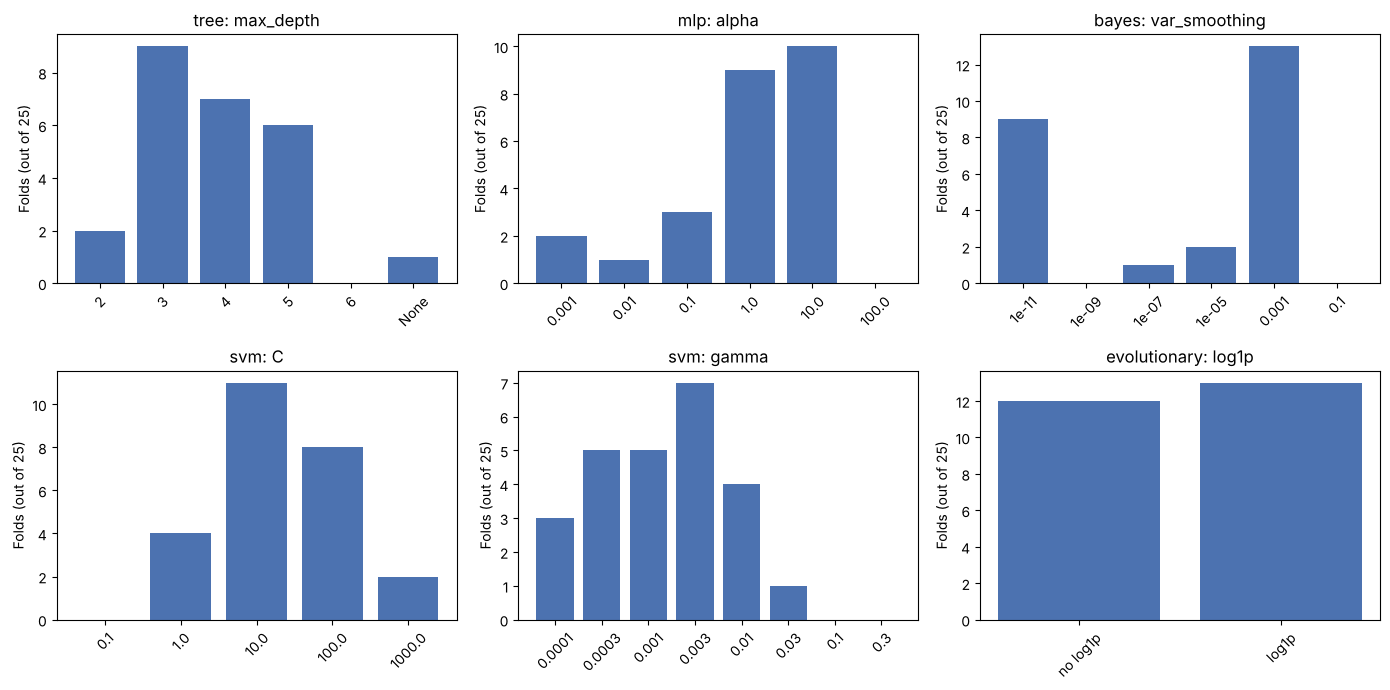

In [11]:
plot_keys = [("tree", "model__max_depth"), ("mlp", "model__alpha"), ("bayes", "model__var_smoothing"), ("svm", "model__estimator__C"), ("svm", "model__estimator__gamma"), ("evolutionary", "log1p")]  # the most informative ones
fig, axes = plt.subplots(2, 3, figsize=(14, 7))  # 2x3 grid
for ax, (key, full_name) in zip(axes.ravel(), plot_keys):  # one plot per hyperparameter
    name = full_name.replace("model__", "").replace("estimator__", "")  # short name
    options = [label(o) for o in learners[key][2][full_name]]  # grid values, in their order
    counts = [chosen[key][name].count(o) for o in options]  # how many folds chose each value
    ax.bar(range(len(options)), counts, color="#4C72B0")  # bars in grid order
    ax.set_xticks(range(len(options)))  # one tick per value
    ax.set_xticklabels(options, rotation=45)  # value names
    ax.set_title(f"{key}: {name}")  # title
    ax.set_ylabel("Folds (out of 25)")  # vertical axis
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "01_chosen_hyperparameters.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** the values of `alpha`, `C` and `max_depth` concentrate; `gamma` and `var_smoothing` are flat (plateaus). A plateau is not a failure: it indicates that several values perform almost equally.

### Cell 12: was the edge of the grid chosen many times?

**Honest check:** if the first or last value of the grid is chosen many times, perhaps the best value is outside and the grid is too short.

In [12]:
for key, (family, _, grid) in learners.items():  # loop over the five
    for full_name, options in grid.items():  # loop over its hyperparameters
        if len(options) < 3:  # with fewer than 3 options "edge" makes no sense
            continue  # skip
        name = full_name.replace("model__", "").replace("estimator__", "")  # short name
        edges = {label(options[0]), label(options[-1])}  # first and last value of the grid
        times = sum(v in edges for v in chosen[key][name])  # folds in which an edge was chosen
        warning = "  <-- check" if times / 25 > 0.4 else ""  # flag if it is frequent
        print(f"{key:12s} {name:20s} edge in {times:2d} of 25 folds{warning}")  # result

tree         max_depth            edge in  3 of 25 folds
tree         min_samples_leaf     edge in 12 of 25 folds  <-- check
mlp          hidden_layer_sizes   edge in 13 of 25 folds  <-- check
mlp          alpha                edge in  2 of 25 folds
bayes        var_smoothing        edge in  9 of 25 folds
svm          C                    edge in  2 of 25 folds
svm          gamma                edge in  3 of 25 folds


**What we see and limits we declare:**
- `min_samples_leaf` touches the edge in 12 of 25, but the lower edge (1) is the smallest possible value: it cannot be extended.
- `hidden_layer_sizes` touches the edges in 13 of 25 (the smallest and the largest): network size matters little.
- `var_smoothing` touches the edge in 9 of 25 (1e-11).

**Grid history:** the current grids are the result of **three widening rounds** during development, because the inner validation was choosing the edges (`alpha`, network size, `var_smoothing`, `gamma`, `C`). Those decisions were taken only from the inner-validation choices: neither the outer-fold scores nor the test set were looked at.

### Cell 13: which thresholds did each learner choose?

Finally, the cost thresholds. A very low threshold (0.03 instead of 0.5) means that the model gives extreme probabilities: even a tumour with a 3% probability is sent for review.

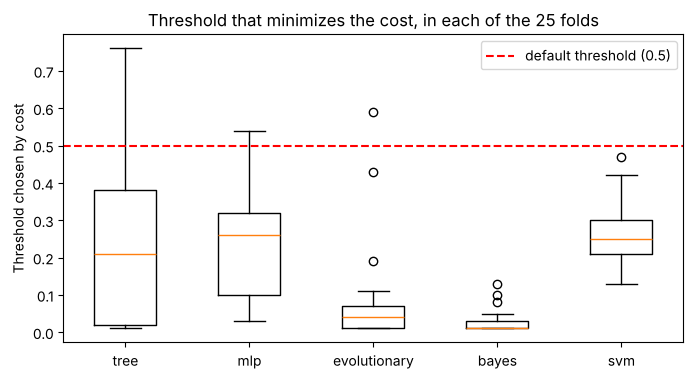

tree         mean threshold 0.21 | min 0.01 | max 0.76 | folds with threshold <= 0.05: 9
mlp          mean threshold 0.24 | min 0.03 | max 0.54 | folds with threshold <= 0.05: 1
evolutionary mean threshold 0.08 | min 0.01 | max 0.59 | folds with threshold <= 0.05: 16
bayes        mean threshold 0.03 | min 0.01 | max 0.13 | folds with threshold <= 0.05: 22
svm          mean threshold 0.26 | min 0.13 | max 0.47 | folds with threshold <= 0.05: 0


In [13]:
fig, ax = plt.subplots(figsize=(8, 4))  # one figure
threshold_data = [results.filter(pl.col("learner") == key)["threshold"].to_numpy() for key in learners]  # the 25 thresholds of each learner
ax.boxplot(threshold_data, tick_labels=list(learners))  # one box per learner
ax.axhline(0.5, color="red", linestyle="--", label="default threshold (0.5)")  # line of the usual threshold
ax.set_ylabel("Threshold chosen by cost")  # vertical axis
ax.set_title("Threshold that minimizes the cost, in each of the 25 folds")  # title
ax.legend()  # legend
plt.savefig(figures_dir / "02_thresholds.png", bbox_inches="tight")  # save
plt.show()  # show
for key in learners:  # numeric summary
    u = results.filter(pl.col("learner") == key)["threshold"]  # thresholds of the learner
    print(f"{key:12s} mean threshold {u.mean():.2f} | min {u.min():.2f} | max {u.max():.2f} | folds with threshold <= 0.05: {int((u <= 0.05).sum())}")  # summary

**What we see:**

| Learner | Mean threshold | Range | Folds with threshold ≤ 0.05 |
|---|---|---|---|
| Tree | 0.21 | 0.01 to 0.76 | 9 |
| MLP | 0.24 | 0.03 to 0.54 | 1 |
| Evolutionary | 0.08 | 0.01 to 0.59 | 16 |
| Naive Bayes | **0.03** | 0.01 to 0.13 | 22 |
| SVM | 0.26 | 0.13 to 0.47 | 0 |

- **[Probable]** Naive Bayes and the evolutionary learner need very low thresholds: their probabilities are extreme and unreliable (the Bayes overconfidence hypothesis points in that direction; it is tested with Brier and log-loss in Phase 6).
- **[Certain]** The tree has very unstable thresholds (from 0.01 to 0.76): its probabilities are almost 0 or 1, so the cost threshold is not reliable. We declare it as a limit.
- MLP and SVM choose moderate, stable thresholds.

### Cell 14: validation curves (does more complexity always help?)

A **validation curve** shows how the score changes when we vary one hyperparameter and keep the others at their default. We draw it for three learners of different kinds (tree depth, MLP regularization `alpha`, SVM `gamma`), using 5-fold cross-validation on the 455 training rows only. The training curve is measured on the data the model saw; the validation curve on data it did not see.

tree | validation MCC by value: {1: 0.789, 2: 0.831, 3: 0.832, 4: 0.831, 5: 0.802, 6: 0.831, 8: 0.836, 10: 0.836} | training MCC at the last value: 1.0


mlp | validation MCC by value: {0.001: 0.931, 0.01: 0.944, 0.1: 0.94, 1: 0.949, 10: 0.94, 100: 0.895} | training MCC at the last value: 0.896


svm | validation MCC by value: {0.0001: 0.843, 0.001: 0.926, 0.01: 0.944, 0.03: 0.949, 0.1: 0.912, 0.3: 0.835, 1: 0.562} | training MCC at the last value: 1.0


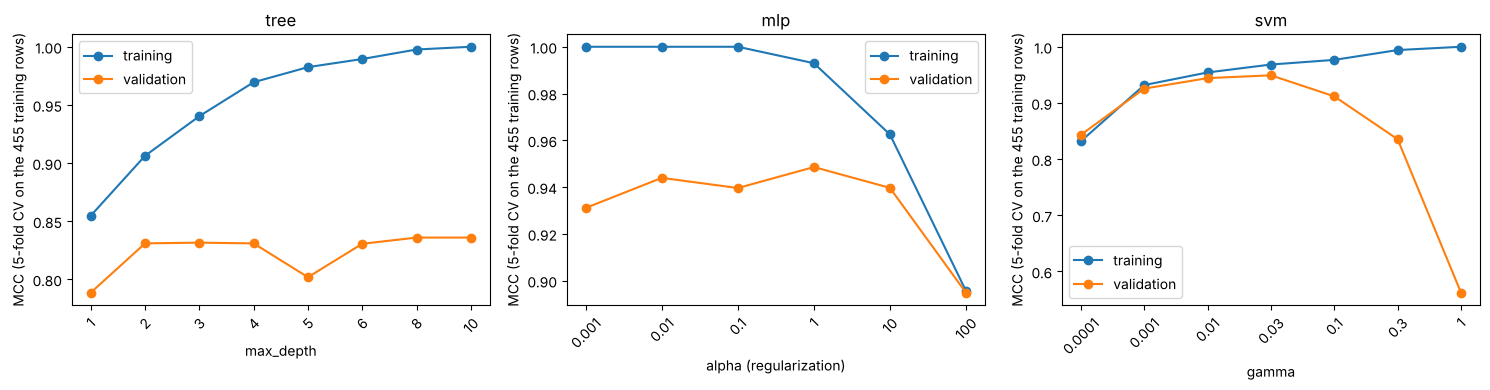

In [14]:
curves = [("tree", "model__max_depth", [1, 2, 3, 4, 5, 6, 8, 10], "max_depth"), ("mlp", "model__alpha", [1e-3, 1e-2, 1e-1, 1, 10, 100], "alpha (regularization)"), ("svm", "model__estimator__gamma", [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1], "gamma")]  # learner, hyperparameter, values to try, axis name
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # one panel per learner
for ax, (key, parameter, values, axis_name) in zip(axes, curves):  # loop over the three learners
    pipeline = learners[key][1]  # the learner's pipeline with its default hyperparameters
    train_mcc, valid_mcc = validation_curve(clone(pipeline), X_train, y_train, param_name=parameter, param_range=values, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring=make_scorer(matthews_corrcoef), n_jobs=-1)  # MCC on the training part and on the validation part of 5 folds
    ax.plot(range(len(values)), train_mcc.mean(axis=1), "o-", label="training")  # curve on the data the model saw
    ax.plot(range(len(values)), valid_mcc.mean(axis=1), "o-", label="validation")  # curve on data it did not see
    ax.set_xticks(range(len(values)))  # one tick per value
    ax.set_xticklabels([str(v) for v in values], rotation=45)  # value names
    ax.set_xlabel(axis_name)  # horizontal axis
    ax.set_ylabel("MCC (5-fold CV on the 455 training rows)")  # vertical axis
    ax.set_title(key)  # title
    ax.legend()  # legend
    print(key, "| validation MCC by value:", {v: round(float(m), 3) for v, m in zip(values, valid_mcc.mean(axis=1))}, "| training MCC at the last value:", round(float(train_mcc.mean(axis=1)[-1]), 3))  # numbers
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "03_validation_curves.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** (1) **Tree:** the training MCC climbs to 1.00 with depth, but the validation MCC stays around 0.83 from depth 2 on (0.79 with depth 1): more complexity only memorizes. (2) **MLP:** validation MCC is 0.93 to 0.95 for `alpha` from 0.001 to 10 and falls to 0.895 at `alpha` = 100, where training also falls (0.896): too much regularization. (3) **SVM:** validation MCC peaks at 0.949 for `gamma` = 0.03 and **collapses to 0.562** at `gamma` = 1 while training reaches 1.00: the kernel becomes so local that each tumour only resembles itself.

**Decision / caution:** the ranges of the grids in Phase 5 cover the useful zone of each curve. These curves keep the other hyperparameters at their default (for example the SVM uses `C` = 1), so their peaks are not the tuned values.

## Summary of the Phase 5 decisions

| Topic | Result |
|---|---|
| Protocol | nested validation 25 outer × 3 inner; criterion MCC; cost threshold with training data |
| Compute cost | ~5 min with 4 cores (MLP the slowest) |
| Stable hyperparameters | tree: depth 3-5; MLP: `alpha` 1-10; Naive Bayes: `log1p`; SVM: `C` 10-100 |
| Plateaus (several values equally good) | SVM `gamma`, `var_smoothing`, network size, `log1p` in MLP, SVM and evolutionary |
| Thresholds | Bayes and evolutionary very low (0.03 and 0.08); tree unstable; MLP and SVM stable (~0.25) |
| Validation curves | tree overfits from depth 2; MLP is best with `alpha` 0.01 to 10; SVM collapses when `gamma` is too large |

**Limits we declare:** grids widened three times with the inner validation; some hyperparameters touch the edges; the tree's threshold is unreliable; the running time is at the limit of "a few minutes".

**Generated files** in `results/`: `outer_folds.csv` (metrics per learner and fold) and `outer_scores.csv` (probability per tumour).

**Next:** Phase 6 · Evaluation: compare the learners with hypothesis tests and use the final test set only once.